# Single Stock Risk Report

A parameterized report for one stock: price, returns, volatility, drawdown
and a summary table. Part 3 runs this notebook for every ticker with papermill.

Data comes from the `ohlc_hw_cleaned` table that `01_data_cleaning.ipynb`
writes to `data/data.db`. Run with this folder as the working directory.

## 2.1 Parameters
This cell is tagged `parameters`, so papermill can override these values.
Two extra parameters: `db_path` points at a different database (handy for
testing), and `metrics_path` lets Part 3 collect this report's numbers.

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Database that holds ohlc_hw_cleaned
metrics_path = ""  # If set, save summary metrics here as JSON (used by Part 3)

In [2]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"
metrics_path = "reports/2026-10-25/IBM_metrics.json"


In [3]:
import json
import sqlite3
from contextlib import closing

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from IPython.display import display

TRADING_DAYS = 252  # trading days per year, used to annualize

## 2.2 Data Loading

The 50-day moving average and 20-day volatility need prices from *before*
`start_date`; without them, the first 50 days of the chart would be blank.
So we load the ticker's full history up to `end_date`, compute those
indicators, and then cut out the requested window.

The end bound uses `ts < end_date + 1 day`, which works whether the
cleaned table stores dates as `2024-12-31` or `2024-12-31 00:00:00`.

The summary line shows the **actual** first and last trading days in the
window, which can differ from the requested dates (holidays, or a ticker
whose data ends early).

In [4]:
start = pd.Timestamp(start_date)
end = pd.Timestamp(end_date)

# Full history up to end_date: the moving average and rolling volatility
# need prices from before start_date.
query = """
SELECT ts, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned
WHERE ticker = ? AND ts < ?
ORDER BY ts
"""
params = (ticker, (end + pd.Timedelta(days=1)).strftime("%Y-%m-%d"))

with closing(sqlite3.connect(db_path)) as conn:
    history = pd.read_sql_query(
        query, conn, params=params, parse_dates=["ts"], index_col="ts"
    )

# Rows in the requested window only (history also has the earlier prices)
data = history.loc[start:end]

if data.empty:
    raise ValueError(f"No data for {ticker} between {start_date} and {end_date}")

MIN_PRICES = 21  # 20 daily returns (one volatility window) need 21 prices
if len(data) < MIN_PRICES:
    raise ValueError(
        f"Insufficient history for {ticker}: only {len(data)} prices between "
        f"{start_date} and {end_date}; at least {MIN_PRICES} are needed for 20 returns."
    )

first_obs, last_obs = data.index.min().date(), data.index.max().date()
print(f"{ticker} from {first_obs} to {last_obs}: {len(data)} trading days")
print(f"(requested window: {start_date} to {end_date})")

IBM from 2024-06-03 to 2024-11-29: 126 trading days
(requested window: 2024-06-01 to 2024-11-30)


In [5]:
display(data.head())
display(data.tail())

,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,166.54,166.78,163.53,165.28,162.57,2776100
2024-06-04,164.60,166.40,163.88,165.81,163.09,2594203
2024-06-05,166.41,167.79,165.78,167.38,164.63,3049400
2024-06-06,167.38,168.44,166.80,168.20,165.44,2207263
2024-06-07,168.18,171.31,168.06,170.01,167.22,3475500


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-11-22,223.35,227.20,220.89,222.97,222.97,5320740
2024-11-25,223.35,226.42,222.65,226.13,226.13,7189300
2024-11-26,226.73,228.98,225.51,228.83,228.83,4449543
2024-11-27,228.83,229.19,224.27,226.92,226.92,2995121
2024-11-29,227.75,230.36,227.19,227.41,227.41,2640300


## 2.3 Risk Metrics

All metrics use `adj_close`, which accounts for splits and dividends,
so a split doesn't show up as a fake crash.

In [6]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns.

    Log return = ln(P_t / P_{t-1}). The first value is NaN because
    there is no previous price.
    """
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility.

    Standard deviation of daily returns over `window` days, scaled by
    sqrt(252) to express it per year.
    """
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Calculate running drawdown from the peak.

    Drawdown = (price - running max) / running max, so it is 0 at a new
    high and negative otherwise. Its minimum is the maximum drawdown.
    """
    cum_max = prices.cummax()
    return (prices - cum_max) / cum_max


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate the annualized Sharpe ratio.

    (annualized mean return - risk-free rate) / annualized volatility.
    Returns NaN when volatility is zero or undefined.
    """
    returns = returns.dropna()
    annual_vol = returns.std() * np.sqrt(TRADING_DAYS)
    if len(returns) < 2 or not np.isfinite(annual_vol) or annual_vol == 0:
        return np.nan
    return (returns.mean() * TRADING_DAYS - risk_free_rate) / annual_vol

Indicators that need history (the 50-day MA and the 20-day volatility)
are computed on `history`, then trimmed. Returns and drawdown are
computed on the window itself, so the drawdown is measured from the
peak *within* the analysis period.

In [7]:
# Indicators computed on the full history, then trimmed to the window
history_returns = calculate_returns(history["adj_close"])
rolling_vol = calculate_volatility(history_returns).loc[start:end]
ma_50 = history["adj_close"].rolling(50).mean().loc[start:end]

# These need earlier prices; if the ticker's history starts inside the window,
# the first values are unavailable (left as gaps, never filled with zero)
for name, series, needed in [("50-day moving average", ma_50, 50),
                             ("20-day volatility", rolling_vol, 21)]:
    n_missing = int(series.isna().sum())
    if n_missing:
        print(f"Note: the {name} needs {needed} prices, so it is unavailable for the "
              f"first {n_missing} days ({ticker}'s data starts on {history.index.min().date()}).")

# Metrics on the analysis window only
prices = data["adj_close"]
returns = calculate_returns(prices).dropna()
drawdown = calculate_max_drawdown(prices)
sharpe = calculate_sharpe_ratio(returns)

metrics = pd.DataFrame({
    "adj_close": prices,
    "ma_50": ma_50,
    "log_return": calculate_returns(prices),
    "rolling_vol_20d": rolling_vol,
    "drawdown": drawdown,
})
display(metrics.tail(10))

print(f"Sharpe ratio:     {sharpe:.2f}")
print(f"Maximum drawdown: {drawdown.min():.2%} on {drawdown.idxmin().date()}")

,adj_close,ma_50,log_return,rolling_vol_20d,drawdown
ts,,,,,
2024-11-15,204.99,217.2068,-0.019325,0.285676,-0.121798
2024-11-18,208.09,217.3298,0.015009,0.294926,-0.108517
2024-11-19,210.25,217.4606,0.010327,0.298959,-0.099263
2024-11-20,214.60,217.5876,0.020479,0.311255,-0.080627
2024-11-21,222.40,217.8364,0.035702,0.251189,-0.047211
2024-11-22,222.97,218.0336,0.002560,0.241515,-0.044769
2024-11-25,226.13,218.2470,0.014073,0.241623,-0.031231
2024-11-26,228.83,218.5744,0.011869,0.236457,-0.019664
2024-11-27,226.92,218.8476,-0.008382,0.212190,-0.027847


Sharpe ratio:     3.22
Maximum drawdown: -12.90% on 2024-10-30


## 2.4 Visualization

One color scheme across all four panels: green = good / low risk,
red = bad / high risk, blue = the main series, gray = reference lines.

The price line is colored by the 20-day volatility on each day: red when it is
above the report's mean volatility, green at or below it, and gray where it
isn't available yet. This is retrospective, since the mean uses the whole window.

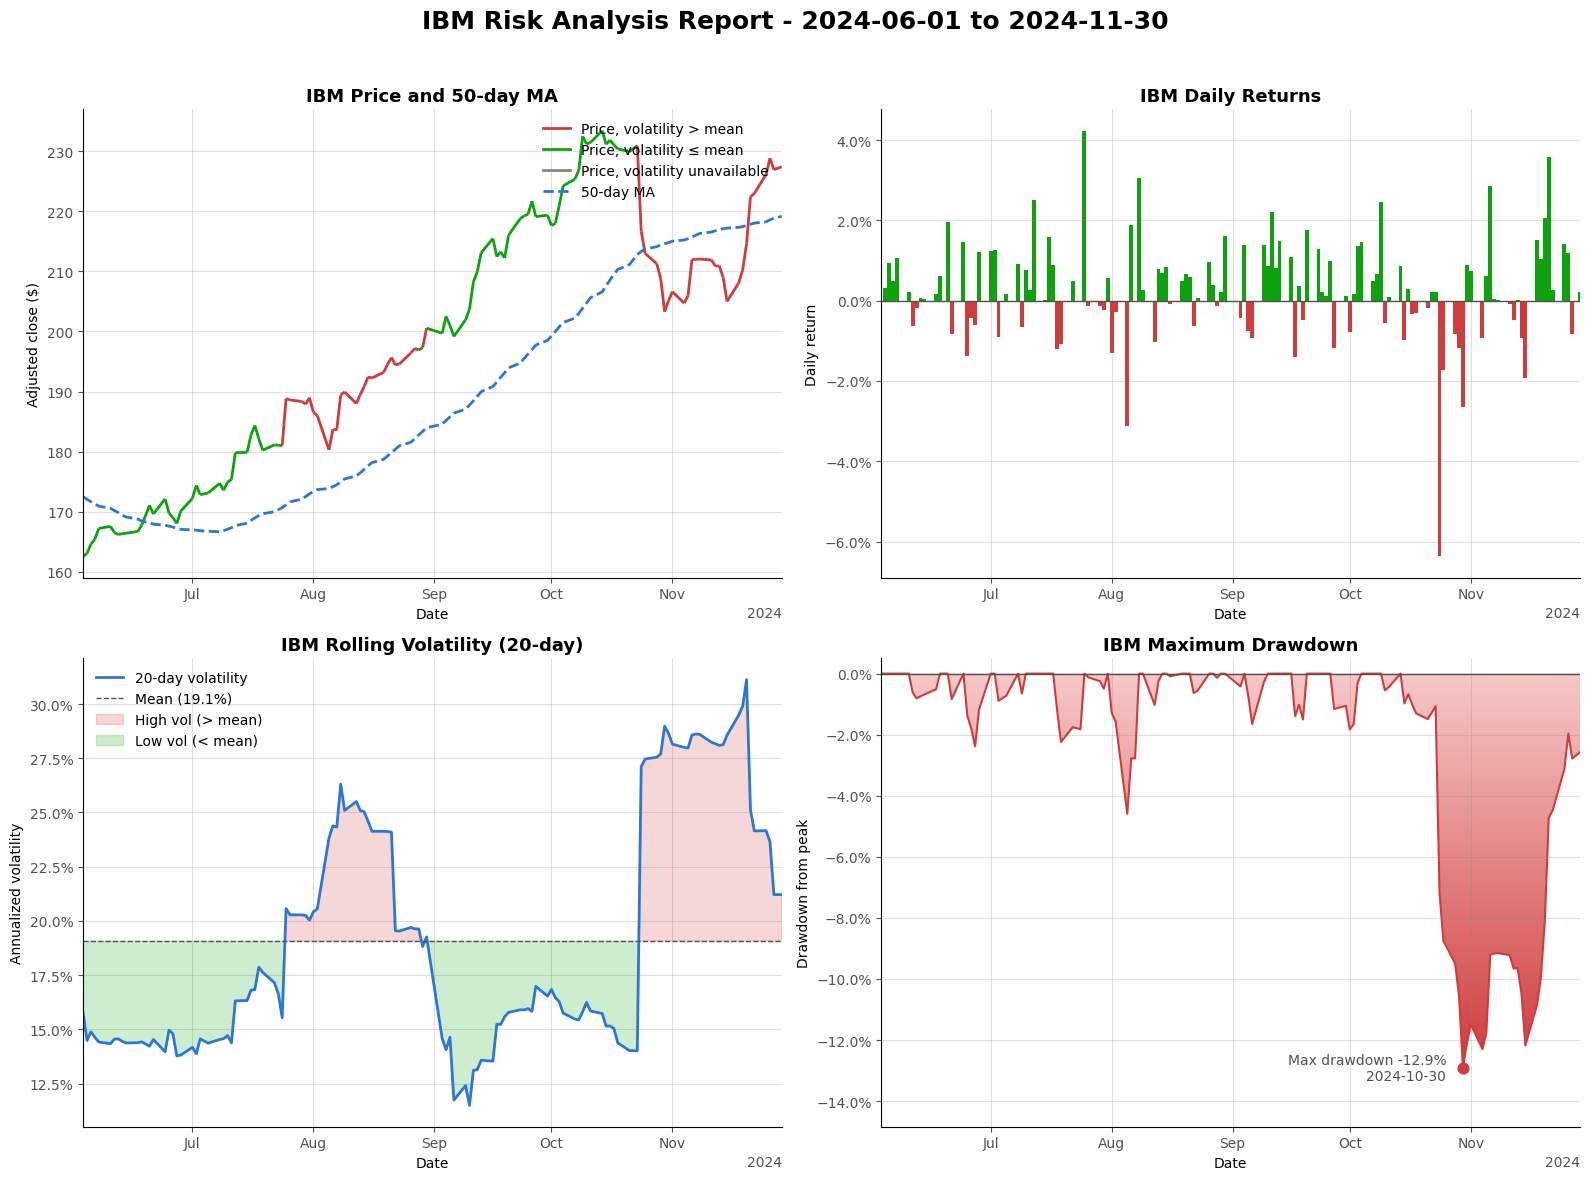

In [8]:
GREEN = "#0ca30c"
RED = "#d03b3b"
PINK = "#f6c9c9"
BLUE = "#2a78d6"
INK = "#52514e"   # reference lines and annotations
MUTED = "#898781"

dd_cmap = LinearSegmentedColormap.from_list("drawdown", [PINK, RED])

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
})

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
ax_price, ax_ret, ax_vol, ax_dd = axes.flat
x = mdates.date2num(prices.index)

# --- Top left: price colored by volatility, plus 50-day MA -------------
# Each segment takes the 20-day volatility at its end date: red above the
# report's mean volatility, green at or below it, gray where it isn't
# available yet. Retrospective: the mean uses the whole report window.
mean_vol = rolling_vol.mean()
points = np.column_stack([x, prices.to_numpy()]).reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
vol_values = rolling_vol.reindex(prices.index).to_numpy()[1:]
segment_colors = np.where(np.isnan(vol_values), MUTED,
                          np.where(vol_values > mean_vol, RED, GREEN))

ax_price.add_collection(LineCollection(segments, colors=segment_colors, linewidth=2))
ax_price.autoscale_view()
ax_price.plot(prices.index, ma_50, color=BLUE, linewidth=2, linestyle="--")

ax_price.legend(handles=[
    Line2D([], [], color=RED, linewidth=2, label="Price, volatility > mean"),
    Line2D([], [], color=GREEN, linewidth=2, label="Price, volatility ≤ mean"),
    Line2D([], [], color=MUTED, linewidth=2, label="Price, volatility unavailable"),
    Line2D([], [], color=BLUE, linewidth=2, linestyle="--", label="50-day MA"),
], loc="best", frameon=False)
ax_price.set_title(f"{ticker} Price and 50-day MA")
ax_price.set_ylabel("Adjusted close ($)")

# --- Top right: daily returns ------------------------------------------
bar_colors = np.where(returns >= 0, GREEN, RED)
ax_ret.bar(returns.index, returns, color=bar_colors,
           width=1.0, linewidth=0)
ax_ret.axhline(0, color=INK, linewidth=1)
ax_ret.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_ret.set_title(f"{ticker} Daily Returns")
ax_ret.set_ylabel("Daily return")

# --- Bottom left: rolling volatility -----------------------------------
ax_vol.plot(rolling_vol.index, rolling_vol, color=BLUE, linewidth=2,
            label="20-day volatility")
ax_vol.axhline(mean_vol, color=INK, linewidth=1, linestyle="--",
               label=f"Mean ({mean_vol:.1%})")
ax_vol.fill_between(rolling_vol.index, rolling_vol, mean_vol,
                    where=rolling_vol >= mean_vol, interpolate=True,
                    color=RED, alpha=0.2, label="High vol (> mean)")
ax_vol.fill_between(rolling_vol.index, rolling_vol, mean_vol,
                    where=rolling_vol < mean_vol, interpolate=True,
                    color=GREEN, alpha=0.2, label="Low vol (< mean)")
ax_vol.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_vol.legend(loc="upper left", frameon=False)
ax_vol.set_title(f"{ticker} Rolling Volatility (20-day)")
ax_vol.set_ylabel("Annualized volatility")

# --- Bottom right: drawdown with a pink-to-red gradient ----------------
# Draw an invisible fill to get its outline, then clip a vertical
# gradient image to that outline: pink near 0, red at the deepest point.
max_dd = drawdown.min()
area = ax_dd.fill_between(x, drawdown, 0, facecolor="none", edgecolor="none")
if max_dd < 0:
    gradient = np.linspace(0, 1, 256).reshape(-1, 1)
    image = ax_dd.imshow(gradient, cmap=dd_cmap, aspect="auto", origin="upper",
                         extent=[x[0], x[-1], max_dd, 0])
    image.set_clip_path(area.get_paths()[0], transform=ax_dd.transData)
ax_dd.plot(x, drawdown, color=RED, linewidth=1.5)
ax_dd.axhline(0, color=INK, linewidth=1)

# Mark the maximum drawdown point
dd_date = drawdown.idxmin()
dd_x = mdates.date2num(dd_date)
ax_dd.scatter(dd_x, max_dd, s=60, color=RED, zorder=3)
# Put the label on whichever side has room
on_right_half = dd_x > (x[0] + x[-1]) / 2
ax_dd.annotate(f"Max drawdown {max_dd:.1%}\n{dd_date:%Y-%m-%d}",
               xy=(dd_x, max_dd), xytext=(-12 if on_right_half else 12, 0),
               textcoords="offset points", ha="right" if on_right_half else "left",
               va="center", color=INK, fontsize=10)
ax_dd.set_ylim(min(max_dd * 1.15, -0.01), 0.005)
ax_dd.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_dd.set_title(f"{ticker} Maximum Drawdown")
ax_dd.set_ylabel("Drawdown from peak")

# --- Shared styling ----------------------------------------------------
for ax in axes.flat:
    ax.set_xlim(x[0], x[-1])  # same date range on every panel
    ax.grid(True, color=MUTED, alpha=0.25)
    ax.set_axisbelow(True)
    ax.set_xlabel("Date")
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.tick_params(colors=INK)

fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}",
             fontsize=18, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 2.5 Summary Statistics

Every return-based statistic uses daily **log returns** of `adj_close`
(missing values removed), as the assignment specifies:

- **Total return:** last adjusted close / first adjusted close − 1.
- **Annualized return:** exp(sum of log returns × 252 / n) − 1, with n returns.
- **Annualized volatility:** std of log returns × √252 for the whole window
  (different from the mean 20-day rolling volatility used in Part 3).
- **Best/worst day, average up/down day:** log returns.
- **Positive days:** positive returns ÷ all returns, so zero-return days count
  in the denominator.

An empty up or down subset shows N/A.

In [9]:
def build_summary(prices: pd.Series, returns: pd.Series,
                  drawdown: pd.Series, sharpe: float) -> dict:
    """Return the report's summary metrics as raw numbers (fractions).

    `returns` are daily log returns of adj_close with missing values removed.
    Day-level statistics (best/worst day, up/down averages) use them as well.
    """
    n = len(returns)
    up, down = returns[returns > 0], returns[returns < 0]

    return {
        "Total Return": prices.iloc[-1] / prices.iloc[0] - 1,
        "Annualized Return": np.exp(returns.sum() * TRADING_DAYS / n) - 1 if n else np.nan,
        "Annualized Volatility": returns.std() * np.sqrt(TRADING_DAYS),
        "Sharpe Ratio": sharpe,
        "Maximum Drawdown": drawdown.min(),
        "Best Day": returns.max(),
        "Worst Day": returns.min(),
        "Positive Days": (returns > 0).mean(),  # zero days stay in the denominator
        "Average Up Day": up.mean() if len(up) else np.nan,
        "Average Down Day": down.mean() if len(down) else np.nan,
    }


def format_metric(name: str, value: float) -> str:
    """Format one metric the way it appears in the report."""
    if pd.isna(value):
        return "N/A"
    if name == "Sharpe Ratio":
        return f"{value:.2f}"
    if name in ("Annualized Volatility", "Positive Days"):
        return f"{value:.2%}"
    return f"{value:+.2%}"  # signed percentages


# Raw numbers (handy for collecting results across tickers in Part 3)
summary_metrics = build_summary(prices, returns, drawdown, sharpe)

summary_table = pd.DataFrame({
    "Metric": list(summary_metrics),
    "Value": [format_metric(k, v) for k, v in summary_metrics.items()],
})
print(summary_table.to_string(index=False))

               Metric   Value
         Total Return +39.88%
    Annualized Return +96.73%
Annualized Volatility  20.42%
         Sharpe Ratio    3.22
     Maximum Drawdown -12.90%
             Best Day  +4.24%
            Worst Day  -6.37%
        Positive Days  63.20%
       Average Up Day  +0.95%
     Average Down Day  -0.92%


### Metrics for the portfolio summary (Part 3)
When `metrics_path` is set, the numbers Part 3 needs are written to a
small JSON file, so the batch script doesn't re-implement these formulas.

In [10]:
portfolio_metrics = {
    "ticker": ticker,
    "start_date": start_date,
    "end_date": end_date,
    "first_date": str(first_obs),  # actual coverage inside the window
    "last_date": str(last_obs),
    "trading_days": len(data),
    "avg_daily_return": float(returns.mean()),  # mean daily log return
    "avg_volatility": float(rolling_vol.mean()),
    "max_drawdown": float(drawdown.min()),
    "sharpe_ratio": float(sharpe),
    "total_return": float(summary_metrics["Total Return"]),
}

if metrics_path:
    with open(metrics_path, "w") as f:
        json.dump(portfolio_metrics, f, indent=2)
    print(f"Saved metrics to {metrics_path}")

Saved metrics to reports/2026-10-25/IBM_metrics.json
